# Home Credit. Разведочный анализ данных

Проверяем качество данных для оценки риска дефолта на момент кредитной заявки. В широкой таблице одна строка соответствует одной заявке (`case_id`). Статистики, связи с целью и квартальные проверки рассчитаны по всем **1 526 659 заявкам**. Для матрицы попарных графиков (`pairplot`) используем выборку.

**Просмотр.** Таблицы и графики уже сохранены в ноутбуке. Для чтения достаточно открыть файл с результатами.

**Повторный запуск.** Откройте ноутбук из корня проекта с pandas, NumPy, matplotlib и seaborn. Нужны следующие входные файлы:

- `outputs/home-credit-full/home_credit_full.csv` и `outputs/home-credit-full/columns.csv` — широкая таблица и её схема. Их собирает `build_home_credit_full_table.py`.
- `outputs/eda-feature-overview/feature_summary_full.csv` и `outputs/eda-feature-overview/working_feature_review.csv` — результаты предварительного аудита.
- `home-credit-credit-risk-model-stability/csv_files/train/train_base.csv` и `home-credit-credit-risk-model-stability/csv_files/train/train_tax_registry_a_1.csv` — исходные таблицы для сверки дат. [Страница данных Home Credit](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability/data)

In [1]:
from pathlib import Path
from io import BytesIO
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display

FULL_DIR = Path("outputs/home-credit-full")
AUDIT_DIR = Path("outputs/eda-feature-overview")
SEED = 20261107

## 1. Исходные поля и дата решения

Предварительный отбор исключает поля с одним известным значением или с пропусками в 90% строк источника и более. Из двух пар точных дублей оставлены `interestrate_311L` и `days360_512L`. Остальные поля входят в широкую таблицу и проверяются на уровне заявки.

In [2]:
keys = ["table", "feature"]
profile = pd.read_csv(AUDIT_DIR / "feature_summary_full.csv").query("role == 'feature'")
review = pd.read_csv(AUDIT_DIR / "working_feature_review.csv")
full_profile = profile[keys + ["full_rows", "full_known_rows", "full_constant_known"]].merge(
    review[keys + ["semantic_type", "coverage_range_pp", "max_distribution_tv"]],
    on=keys, how="left", validate="one_to_one",
)
full_profile["missing_row_pct"] = (
    100 * (full_profile.full_rows - full_profile.full_known_rows) / full_profile.full_rows
)
working = full_profile.loc[full_profile.semantic_type.notna()].copy()
working["unstable_before_aggregation"] = (
    working.coverage_range_pp.ge(10) | working.max_distribution_tv.ge(.20)
)
assert len(full_profile) == 464 and len(working) == 357
filtered = full_profile.full_constant_known | full_profile.missing_row_pct.ge(90)
display(pd.Series({
    "Исходных полей": len(full_profile),
    "Исключено по пропускам или константам": int(filtered.sum()),
    "Исключено как точные дубли": 2,
    "Полей в широком анализе": len(working),
}, name="Полей").to_frame())

,Полей
Исходных полей,464
Исключено по пропускам или константам,105
Исключено как точные дубли,2
Полей в широком анализе,357


### Налоговый реестр на дату заявки

Сопоставляем строки `tax_registry_a_1` с датой решения по `case_id`. Проверяем уникальность ключа базы при объединении и сравниваем даты на всех строках реестра.

In [3]:
train_dir = Path("home-credit-credit-risk-model-stability/csv_files/train")
decision_dates = pd.read_csv(train_dir / "train_base.csv", usecols=["case_id", "date_decision"])
registry_dates = pd.read_csv(
    train_dir / "train_tax_registry_a_1.csv", usecols=["case_id", "recorddate_4527225D"]
)
assert decision_dates.case_id.notna().all() and registry_dates.case_id.notna().all()
registry_dates = registry_dates.merge(decision_dates, on="case_id", how="left", validate="many_to_one")
assert registry_dates.date_decision.notna().all()

record_date = pd.to_datetime(registry_dates.recorddate_4527225D, format="%Y-%m-%d")
decision_date = pd.to_datetime(registry_dates.date_decision, format="%Y-%m-%d")
offset = (record_date - decision_date).dt.days
display(pd.Series({
    "Заявок с записями реестра": registry_dates.case_id.nunique(),
    "Строк реестра": len(registry_dates),
    "Строк с датой до решения": offset.lt(0).sum(),
    "Строк с датой в день решения": offset.eq(0).sum(),
    "Строк с датой после решения": offset.gt(0).sum(),
    "Строк без даты записи": offset.isna().sum(),
    "Минимальное смещение, дней": offset.min(),
    "Максимальное смещение, дней": offset.max(),
}, name="Результат").to_frame())
del decision_dates, registry_dates, record_date, decision_date, offset

,Результат
Заявок с записями реестра,457934
Строк реестра,3275770
Строк с датой до решения,0
Строк с датой в день решения,0
Строк с датой после решения,3275770
Строк без даты записи,0
"Минимальное смещение, дней",3
"Максимальное смещение, дней",14


Во всех **3 275 770 строках** по **457 934 заявкам** дата записи позже решения на **3–14 дней**. Фильтр по этой дате убрал бы весь источник. Организаторы поясняют, что внешние данные собраны на дату заявки, даты преобразованы, а более поздняя дата этого поля ожидаема. Для EDA сохраняем три агрегата реестра как снимок. Время получения этих данных в рабочей системе по выгрузке установить нельзя. [Разъяснение организаторов](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability/discussion/472866)

## 2. Качество данных и исправления

Статические поля присоединены по заявке. Для истории используем среднее числовых значений, первую известную категорию по порядку данных или последнюю известную дату относительно решения. Где есть подходящая дата события, отбираем записи до или на дату решения. Для платежей, датированных только месяцем, берём полностью предшествующие месяцы.

Проверяем ключ заявки, бинарную цель, диапазоны и хронологию. Пропуски учитываем отдельно от нулей.

In [4]:
schema = pd.read_csv(FULL_DIR / "columns.csv").rename(columns={"source": "table", "field": "feature"})
features_schema = working.merge(
    schema.loc[schema.feature.notna(), ["table", "feature", "column", "aggregation"]],
    on=["table", "feature"], validate="one_to_one"
)
assert len(features_schema) == len(working)
assert features_schema.column.is_unique
feature_names = features_schema.column.tolist()
numeric_columns = features_schema.loc[
    features_schema.semantic_type.str.startswith("numeric") | features_schema.semantic_type.eq("date"),
    "column",
].tolist()
numeric_set = set(numeric_columns)
diagnostics = [f"{table}__{name}" for table in sorted(features_schema.table.unique())
               for name in ("records_raw", "records_used")]
base_columns = ["case_id", "date_decision", "MONTH", "WEEK_NUM", "target"]
dtypes = {c: ("float64" if c in numeric_set else "category") for c in feature_names}
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The 'float_precision' argument is deprecated.*")
    data = pd.read_csv(FULL_DIR / "home_credit_full.csv",
                       usecols=base_columns + diagnostics + feature_names, dtype=dtypes,
                       float_precision="round_trip")
assert len(data) == 1_526_659 and data.case_id.notna().all() and data.case_id.is_unique
assert data.target.notna().all() and set(data.target.unique()) == {0, 1}
assert all(isinstance(data[name].dtype, pd.CategoricalDtype) for name in feature_names if name not in numeric_set)
decision = pd.to_datetime(data.date_decision, format="%Y-%m-%d", errors="raise")
assert decision.notna().all()
y = data.target
class_counts = y.value_counts().sort_index()
print(f"Период решений — {decision.min().date()} – {decision.max().date()}")
display(pd.DataFrame({"Заявок": class_counts, "Доля, %": (100 * class_counts / len(y)).round(3)}))

by_field = features_schema.set_index(["table", "feature"]).column

def feature(table, name):
    return data[by_field.loc[(table, name)]]

Период решений — 2019-01-01 – 2020-10-05


,Заявок,"Доля, %"
target,,
0,1478665,96.856
1,47994,3.144


### Типы признаков

Считаем типы для **357 признаков** широкой таблицы. При загрузке числовые значения и смещения дат читаем как `float64`, а категории, календарные коды и флаги — как `category`. Поэтому в признаках нет столбцов `object`. Разделение числовых полей на целые и дробные относится к значениям в исходных таблицах. После агрегации среднее целых значений может быть дробным.

In [5]:
feature_dtypes = data.dtypes.loc[feature_names].astype(str)
dtype_counts = feature_dtypes.value_counts()
dtype_counts = dtype_counts.reindex(dtype_counts.index.union(["object", "int64"], sort=False), fill_value=0)
assert dtype_counts.sum() == len(feature_names)
display(dtype_counts.rename_axis("Тип pandas").rename("Признаков").to_frame())

type_labels = {
    "numeric_integer_observed": "Числовые, целые в источнике",
    "numeric_fractional": "Числовые, дробные в источнике",
    "date": "Даты, представленные смещением в днях",
    "categorical": "Категории",
    "calendar_component": "Календарные компоненты",
    "binary": "Двоичные флаги",
    "record_index": "Индексы записей",
}
semantic_counts = features_schema.semantic_type.value_counts().rename(index=type_labels)
display(semantic_counts.rename_axis("Тип по смыслу").rename("Признаков").to_frame())

,Признаков
Тип pandas,
float64,248
category,109
object,0
int64,0


,Признаков
Тип по смыслу,
"Числовые, целые в источнике",118
Категории,87
"Числовые, дробные в источнике",85
"Даты, представленные смещением в днях",45
Календарные компоненты,16
Двоичные флаги,5
Индексы записей,1


### Три исправления с проверяемым основанием

- **Доля досрочных платежей `pctinstlsallpaidearl3d_427L`.** Проверка связанных счётчиков не подтвердила деление на 100 и не дала формулы, которая надёжно восстанавливает долю. Значения вне 0–1 заменяем на пропуски.
- **Дата предыдущей заявки `lastapplicationdate_877D`.** На пересечении допустимые даты совпали с датой создания из истории в 99,30% случаев. Для дат позже решения подставляем последнюю допустимую дату из истории, если она есть. В остальных случаях оставляем пропуск.
- **Оставшиеся взносы `numberofoutstandinstls_520L`.** Проверка исходной истории показала, что ошибочная запись завышает среднее по заявке до 450 000. После исключения этой записи среднее равно 0.

Сохраняем журнал правок в `eda_quality_corrections.csv`. Расчёты ниже используют исправленные значения.

In [6]:
correction_parts = []

def apply_quality_correction(table, name, changed, replacement, reason):
    column = by_field.loc[(table, name)]
    old = data[column].copy()
    replacement = pd.Series(replacement, index=data.index, dtype="float64")
    new = old.mask(changed, replacement)
    assert int(changed.sum()) == int((~(old.eq(new) | (old.isna() & new.isna()))).sum())
    correction_parts.append(pd.DataFrame({
        "case_id": data.loc[changed, "case_id"].to_numpy(),
        "column": column, "old_value": old.loc[changed].to_numpy(),
        "new_value": new.loc[changed].to_numpy(),
        "reason": pd.Series(reason, index=data.index).loc[changed].to_numpy(),
    }))
    data[column] = new


ratio_key = ("static_0", "pctinstlsallpaidearl3d_427L")
ratio = feature(*ratio_key)
outside_ratio = ratio.notna() & ~ratio.between(0, 1)
apply_quality_correction(*ratio_key, outside_ratio, np.nan, "Доля вне 0–1, точное значение неизвестно")
assert feature(*ratio_key).dropna().between(0, 1).all()

date_key = ("static_0", "lastapplicationdate_877D")
future = feature(*date_key).gt(0)
history_date = feature("applprev_1", "creationdate_885D")
safe_date = history_date.where(history_date.le(0))
date_reason = np.where(safe_date.notna(), "Дата подставлена из истории",
                       "Дата позже решения, допустимой даты в истории нет")
apply_quality_correction(*date_key, future, safe_date, date_reason)
assert feature(*date_key).dropna().le(0).all()

counter_key = ("credit_bureau_a_1", "numberofoutstandinstls_520L")
counter_case = feature(*counter_key).eq(450_000)
assert counter_case.sum() == 1
apply_quality_correction(*counter_key, counter_case, 0.0, "Среднее пересчитано без ошибочной записи")

quality_corrections = pd.concat(correction_parts, ignore_index=True)
assert not quality_corrections[["case_id", "column"]].duplicated().any()
assert len(data) == 1_526_659 and data.case_id.is_unique
quality_corrections.to_csv(FULL_DIR / "eda_quality_corrections.csv", index=False)
display(quality_corrections.groupby("reason", sort=False).size().rename("Изменённых ячеек").to_frame())


,Изменённых ячеек
reason,
"Доля вне 0–1, точное значение неизвестно",34202
"Дата позже решения, допустимой даты в истории нет",13557
Дата подставлена из истории,100679
Среднее пересчитано без ошибочной записи,1


In [7]:
birth_offset = feature("person_1", "birth_259D")
birth_after_decision = birth_offset.gt(0)
birth = decision + pd.to_timedelta(birth_offset.mask(birth_after_decision), unit="D")
birthday_pending = (decision.dt.month * 100 + decision.dt.day) < (birth.dt.month * 100 + birth.dt.day)
age = decision.dt.year - birth.dt.year - birthday_pending.astype(int)
future_creation = feature("applprev_1", "creationdate_885D").gt(0)
assert not future_creation.any()
display(pd.Series({
    "Заявок с известным возрастом": int(age.notna().sum()),
    "Минимальный возраст, лет": int(age.min()),
    "Максимальный возраст, лет": int(age.max()),
    "Дат рождения позже решения": int(birth_after_decision.sum()),
    "Дат создания прошлой заявки позже решения": int(future_creation.sum()),
}, name="Результат").to_frame())

settled = feature("static_0", "totalsettled_863A")
assert settled.dropna().ge(0).all()
settled_log = np.log1p(settled)

,Результат
Заявок с известным возрастом,1526659
"Минимальный возраст, лет",20
"Максимальный возраст, лет",76
Дат рождения позже решения,0
Дат создания прошлой заявки позже решения,0


Возраст основного заявителя составляет 20–76 лет. После отбора в истории нет дат создания предыдущей заявки позже решения.

В исходных строках `credit_bureau_a_1.overdueamount_659A` максимум составил **437 339 700**, а 99-й процентиль по выборке из 16 683 известных значений — около **5 906**. Такая разница указывает на экстремум. Значение сохраняем, пока нет основания считать его ошибкой.

## 3. Описательная статистика, пропуски и связь с дефолтом

Для числовых полей считаем среднее, разброс и квантили, для категориальных — число уровней и частоты. Связь числовых полей и смещений дат с дефолтом оцениваем коэффициентом Спирмена по заполненным заявкам. Считаем его для непостоянных полей, у которых не менее 1 000 известных значений и в этой группе есть оба исхода. Для категорий сравниваем доли дефолтов среди максимум восьми частых уровней с не менее чем 1 000 заявок на уровень.

В рейтингах сортируем по модулю коэффициента, но показываем его со знаком. Охват — доля всех заявок, где известно значение признака. Второй рейтинг использует охват от 50%, чтобы отдельно посмотреть на связи в более распространённых полях. Полный отчёт по 357 признакам сохраняется в `eda_feature_report.csv`.

In [8]:
MIN_GROUP = 1_000
QUANTILES = [.01, .25, .5, .75, .99]

def rate(events, size):
    return 100 * events / size if size else np.nan

def describe_and_link(column, numeric):
    known = column.notna()
    n = int(known.sum())
    missing = len(y) - n
    y_known = y[known]
    events = int(y_known.sum())
    row = {"known_cases": n, "missing_cases": missing, "missing_pct": 100 * missing / len(y),
           "events_known": events, "events_missing": positive_total - events,
           "target_1_known_pct": rate(events, n), "target_1_missing_pct": rate(positive_total - events, missing),
           "spearman": np.nan, "category_gap_pp": np.nan, "supported_categories": 0}
    if numeric:
        x = column[known]
        assert np.isfinite(x).all(), column.name
        stats = x.describe(percentiles=QUANTILES)
        row.update(stats.drop("count").rename({"1%": "q01", "25%": "q25", "50%": "q50",
                                               "75%": "q75", "99%": "q99"}).to_dict())
        row["zero_pct_known"] = 100 * x.eq(0).mean()
        row["constant_known"] = bool(n and stats["min"] == stats["max"])
        if n >= MIN_GROUP and 0 < events < n and not row["constant_known"]:
            row["spearman"] = x.rank(method="average").corr(y_known)
    else:
        counts = y.groupby(column, observed=True, dropna=True).agg(["size", "sum"])
        assert int(counts["size"].sum()) == n
        row["unique"] = len(counts)
        row["constant_known"] = len(counts) == 1
        if len(counts):
            top = counts["size"].idxmax()
            row["top"] = str(top)
            row["freq"] = int(counts.loc[top, "size"])
        supported = counts.loc[counts["size"].ge(MIN_GROUP)].nlargest(8, "size")
        row["supported_categories"] = len(supported)
        if len(supported) >= 2:
            rates = 100 * supported["sum"] / supported["size"]
            row["category_gap_pp"] = rates.max() - rates.min()
    return row


positive_total = int(y.sum())
calculated = pd.DataFrame([describe_and_link(data[c], c in numeric_set) for c in feature_names])
identity = features_schema[["table", "feature", "column", "aggregation", "semantic_type",
                            "missing_row_pct", "unstable_before_aggregation"]].reset_index(drop=True)
feature_report = pd.concat([identity, calculated], axis=1, verify_integrity=True)
assert len(feature_report) == 357 and feature_report.column.is_unique
assert feature_report.known_cases.add(feature_report.missing_cases).eq(len(y)).all()
assert feature_report.events_known.add(feature_report.events_missing).eq(positive_total).all()
feature_report.to_csv(FULL_DIR / "eda_feature_report.csv", index=False)

report = feature_report.set_index(["table", "feature"])
rare = report.missing_cases.mul(10).ge(9 * len(y))
zero_heavy = report.semantic_type.str.startswith("numeric") & report.zero_pct_known.ge(90)
display(pd.Series({
    "Пропуски у ≥90% заявок": int(rare.sum()),
    "Числовые поля с ≥90% нулей среди известных": int(zero_heavy.sum()),
    "Одно известное значение": int(report.constant_known.sum()),
    "Полностью пустые поля": int(report.known_cases.eq(0).sum()),
}, name="Полей").to_frame())

display(Markdown("**Примеры числовых полей**"))
numeric_examples = [
    ("static_0", "credamount_770A"),
    ("static_0", "totalsettled_863A"),
    ("static_0", "avgdpdtolclosure24_3658938P"),
]
display(report.loc[numeric_examples, ["missing_pct", "mean", "std", "q50", "q99", "max"]]
        .round(2).rename(columns={
            "missing_pct": "Пропуски, %", "mean": "Среднее", "std": "Ст. отклонение",
            "q50": "Медиана", "q99": "99-й процентиль", "max": "Максимум",
        }))

display(Markdown("**Примеры категориальных полей**"))
category_examples = [
    ("static_0", "credtype_322L"),
    ("applprev_1", "postype_4733339M"),
    ("credit_bureau_a_1", "description_351M"),
]
display(report.loc[category_examples, ["missing_pct", "unique", "top", "freq", "category_gap_pp"]]
        .round(2).rename(columns={
            "missing_pct": "Пропуски, %", "unique": "Уровней", "top": "Частый уровень",
            "freq": "Заявок с ним", "category_gap_pp": "Размах дефолтов, п.п.",
        }))

spearman_rank = (
    report.loc[report.spearman.notna(), ["spearman", "known_cases", "events_known", "missing_pct"]]
    .assign(coverage_pct=lambda rows: 100 - rows.missing_pct)
    .sort_values("spearman", key=lambda values: values.abs(), ascending=False, kind="stable")
)
broad_coverage = spearman_rank.loc[spearman_rank.known_cases.mul(2).ge(len(y))]
display(Markdown(
    f"**Спирмен с дефолтом.** Коэффициент рассчитан для **{len(spearman_rank)} "
    f"из {len(numeric_columns)}** числовых полей и смещений дат."
))
rank_labels = {
    "spearman": "Спирмен", "known_cases": "Заявок", "events_known": "Дефолтов", "coverage_pct": "Охват, %",
}
for caption, ranking, limit in [
    ("Топ-8 по абсолютному Спирмену", spearman_rank, 8),
    ("Топ-10 среди полей с охватом от 50%", broad_coverage, 10),
]:
    display(Markdown(f"**{caption}**"))
    display(ranking.head(limit)[list(rank_labels)]
            .rename(columns=rank_labels).rename_axis(["Источник", "Признак"])
            .round({"Спирмен": 3, "Охват, %": 2}))

def event_rates(groups):
    return (y.groupby(groups, observed=True, dropna=False)
            .agg(cases="size", events="sum", target_1_pct="mean")
            .assign(target_1_pct=lambda frame: 100 * frame.target_1_pct).round(3))


static_availability = pd.Series(np.select(
    [data["static_cb_0__records_raw"].eq(0), feature("static_cb_0", "contractssum_5085716L").isna()],
    ["Нет строки источника", "Строка есть, поле пустое"], default="Поле заполнено",
), index=y.index)
display(Markdown("**Дефолты и доступность суммы контрактов**"))
display(event_rates(static_availability)
        .rename(columns={"cases": "Заявок", "events": "Дефолтов", "target_1_pct": "Доля дефолтов, %"}))

,Полей
Пропуски у ≥90% заявок,59
Числовые поля с ≥90% нулей среди известных,36
Одно известное значение,4
Полностью пустые поля,2


**Примеры числовых полей**

Пропуски, %  ...    Максимум
table    feature                                   ...            
static_0 credamount_770A                      0.0  ...    950000.0
         totalsettled_863A                    0.0  ...  48035036.0
         avgdpdtolclosure24_3658938P         30.6  ...      4750.0

[3 rows x 6 columns]

**Примеры категориальных полей**

,,"Пропуски, %",Уровней,Частый уровень,Заявок с ним,"Размах дефолтов, п.п."
table,feature,,,,,
static_0,credtype_322L,0.00,3.0,COL,988376.0,0.35
applprev_1,postype_4733339M,20.94,9.0,a55475b1,751296.0,3.16
credit_bureau_a_1,description_351M,9.20,12.0,a55475b1,1373487.0,12.78


**Спирмен с дефолтом.** Коэффициент рассчитан для **246 из 248** числовых полей и смещений дат.

... (2 outputs left out)

**Топ-10 среди полей с охватом от 50%**

Спирмен  ...  Охват, %
Источник          Признак                                   ...          
static_0          avgdpdtolclosure24_3658938P        0.129  ...     69.40
                  avgmaxdpdlast9m_3716943P           0.114  ...     50.41
                  maxdbddpdtollast12m_3658940P       0.112  ...     53.79
credit_bureau_a_2 pmts_dpd_303P                      0.112  ...     66.29
                  pmts_overdue_1152A                 0.110  ...     66.29
static_0          pctinstlsallpaidlate1d_3546856L    0.107  ...     69.95
                  numinstlswithdpd10_728L            0.105  ...     70.10
credit_bureau_a_1 dpdmax_757P                        0.105  ...     59.31
applprev_1        maxdpdtolerance_577P               0.105  ...     70.32
credit_bureau_a_2 pmts_dpd_1073P                     0.104  ...     81.14

[10 rows x 4 columns]

**Дефолты и доступность суммы контрактов**

,Заявок,Дефолтов,"Доля дефолтов, %"
Нет строки источника,26183,779,2.975
Поле заполнено,157329,3217,2.045
"Строка есть, поле пустое",1343147,43998,3.276


У просроченной суммы из бюро B самый высокий Спирмен (**0,176**), но он рассчитан на **2,38%** заявок. У статического показателя средних дней просрочки связь слабее (**0,129**) и охват выше (**69,40%**). Коэффициенты относятся к разным группам заявок, поэтому читаем их вместе с охватом.

У суммы контрактов доля дефолтов **2,05%** среди заявок с известным значением и **3,28%** там, где есть запись источника, но поле пустое. Пропуск сохраняем отдельным состоянием. Различие предстоит проверить на более позднем периоде.

## 4. Что показывают связи и распределения

### Тепловая карта Спирмена

Проверяем, какие признаки изменяются вместе и какие связаны с дефолтом. Выбрали восемь полей с охватом от 50%. Среди них суммы, история прошлых заявок и показатели просрочки. Каждая ячейка показывает Спирмена на заявках, где известны оба значения. Положительный коэффициент означает, что большие значения одного поля чаще встречаются вместе с большими значениями другого. Нижняя строка показывает связь с `target`, где 1 означает дефолт.

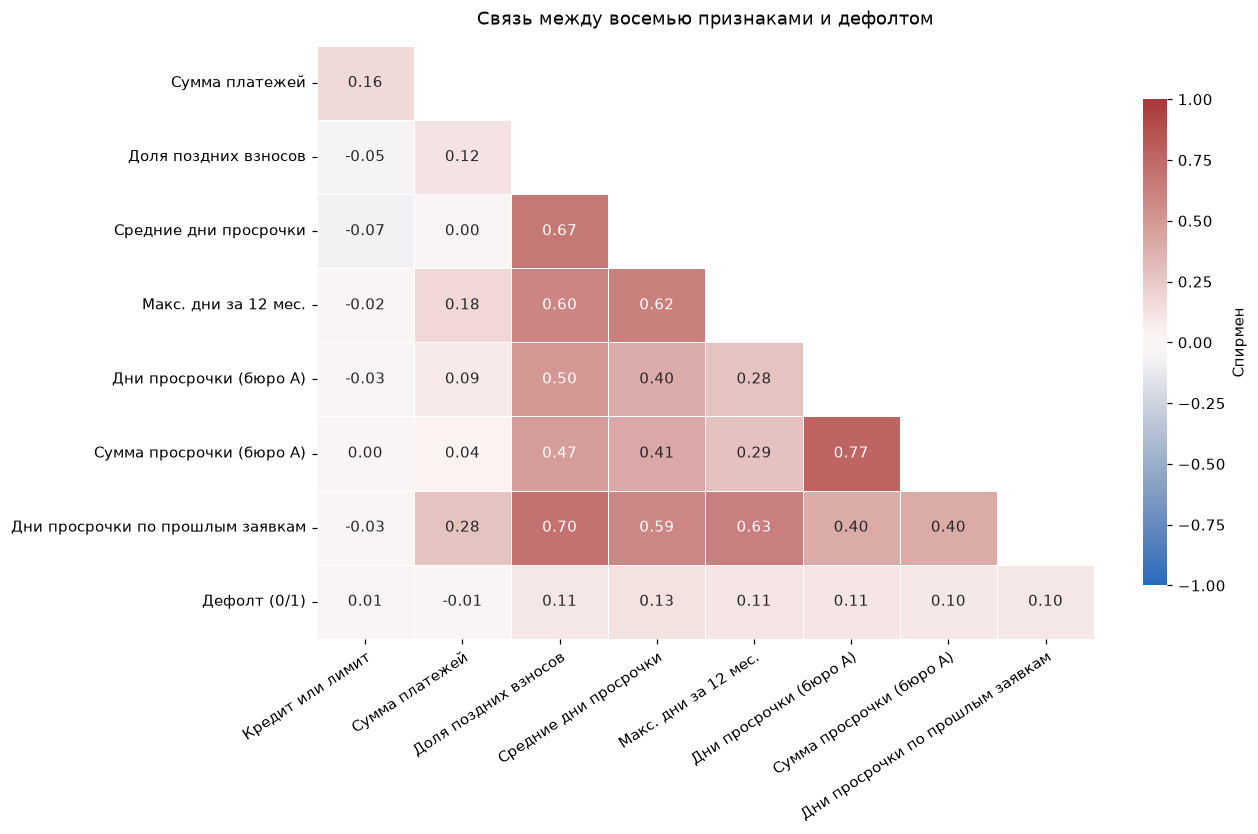

In [9]:
def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


heatmap_fields = {
    "Кредит или лимит": ("static_0", "credamount_770A"),
    "Сумма платежей": ("static_0", "totalsettled_863A"),
    "Доля поздних взносов": ("static_0", "pctinstlsallpaidlate1d_3546856L"),
    "Средние дни просрочки": ("static_0", "avgdpdtolclosure24_3658938P"),
    "Макс. дни за 12 мес.": ("static_0", "maxdbddpdtollast12m_3658940P"),
    "Дни просрочки (бюро A)": ("credit_bureau_a_2", "pmts_dpd_303P"),
    "Сумма просрочки (бюро A)": ("credit_bureau_a_1", "overdueamountmax2_398A"),
    "Дни просрочки по прошлым заявкам": ("applprev_1", "maxdpdtolerance_577P"),
}
heatmap_data = pd.DataFrame({label: feature(*key) for label, key in heatmap_fields.items()})
heatmap_data["Дефолт (0/1)"] = y
assert heatmap_data.notna().sum().mul(2).ge(len(y)).all()
heatmap_corr = heatmap_data.corr(method="spearman", min_periods=MIN_GROUP)
visible_corr = heatmap_corr.iloc[1:, :-1]
rounded = visible_corr.round(2)
rounded = rounded.mask(rounded.eq(0), 0.0)
fig, ax = plt.subplots(figsize=(11.4, 7.0))
sns.heatmap(visible_corr, mask=np.triu(np.ones_like(visible_corr, dtype=bool), k=1),
            annot=rounded, fmt=".2f", vmin=-1, vmax=1, cmap="vlag",
            linewidths=.45, cbar_kws={"label": "Спирмен", "shrink": .82}, ax=ax)
ax.set_title("Связь между восемью признаками и дефолтом", pad=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=33, ha="right", rotation_mode="anchor")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
show_figure(fig)

У доли поздних взносов и средних дней просрочки Спирмен около **0,67**. Эти поля отражают похожую сторону кредитной истории. Чтобы решать, можно ли убрать одно из них, отдельно смотрим на совпадение значений и охват. В разделе 6 есть полный расчёт Пирсона для 21 493 пар и Спирмен для выбранных пар.

### Попарные графики (`pairplot`)

Смотрим, как именно выглядят совместные распределения трёх полей. На диагонали показаны распределения отдельных полей, каждое со своей вертикальной шкалой. Ниже показаны пары признаков. Точка означает одну заявку, цвет — её исход. Берём случайные 2 500 заявок, где заполнены все три поля. Преобразование `log1p` (логарифм от `1 + x`) сжимает длинные хвосты сумм и дней, сохраняя ноль.

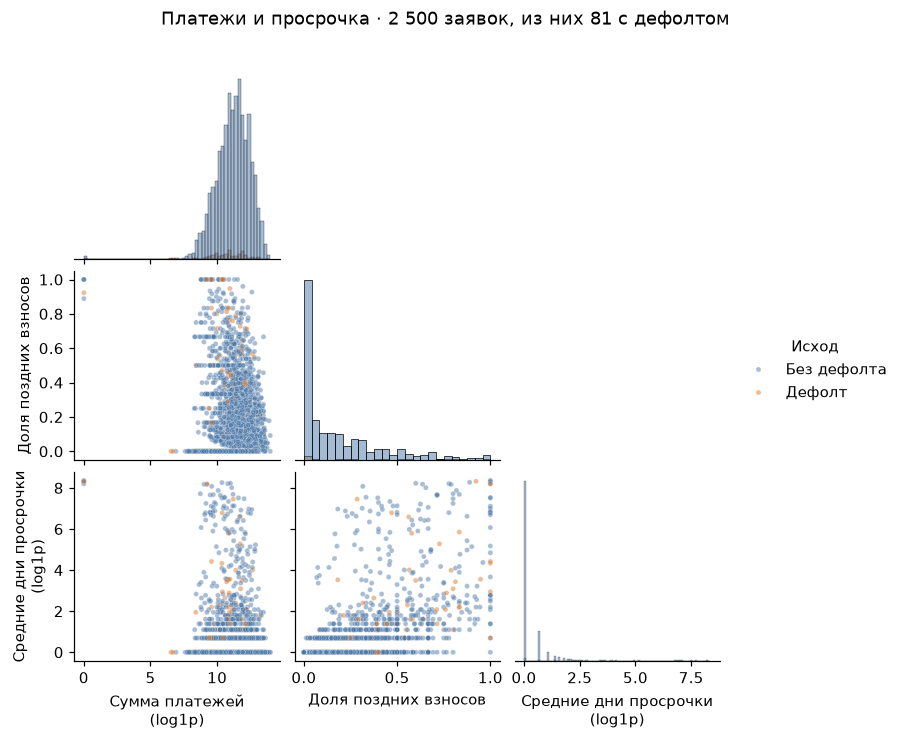

In [10]:
days = heatmap_data["Средние дни просрочки"]
assert days.dropna().ge(0).all()
pair_data = pd.DataFrame({
    "Сумма платежей\n(log1p)": settled_log,
    "Доля поздних взносов": heatmap_data["Доля поздних взносов"],
    "Средние дни просрочки\n(log1p)": np.log1p(days),
    "Исход": y,
}).dropna()
pair_sample = pair_data.sample(n=min(2_500, len(pair_data)), random_state=SEED).copy()
assert pair_sample["Исход"].nunique() == 2
sample_events = int(pair_sample["Исход"].sum())
pair_sample["Исход"] = pair_sample["Исход"].map({0: "Без дефолта", 1: "Дефолт"})
grid = sns.pairplot(pair_sample, vars=pair_data.columns[:-1].tolist(), hue="Исход",
                    palette={"Без дефолта": "#4C78A8", "Дефолт": "#DB7529"},
                    corner=True, diag_kind="hist", height=2.25,
                    grid_kws={"diag_sharey": False}, plot_kws={"s": 11, "alpha": .48})
sample_size = f"{len(pair_sample):,}".replace(",", " ")
grid.figure.suptitle(f"Платежи и просрочка · {sample_size} заявок, из них {sample_events} с дефолтом", y=.99)
grid.figure.subplots_adjust(top=.91)
show_figure(grid.figure)
del heatmap_data, pair_data

На графике видно скопление заявок с нулём по средним дням просрочки и с малой долей поздних взносов. Это нули среди заполненных заявок. Пропуски учитываем отдельно. Цвет помогает увидеть, насколько классы перекрываются в этой выборке.

## 5. Что меняется по кварталам

Сравниваем семь полных кварталов с 2019Q1 по 2020Q3. Отдельно сравниваем долю заявок с известным значением и распределение среди заполненных заявок. Ставим флаг при размахе охвата от 10 п.п. или при расстоянии полной вариации (`TV`) от 0,20. TV равно 0, если доли по группам совпадают, и достигает 1, если группы полностью различаются. У числовых полей сравниваем доли в фиксированных интервалах с отдельной группой для нуля. У категориальных сравниваем частоты кодов. Для сравнения распределений нужно не менее 1 000 заполненных заявок в каждом из сравниваемых кварталов.

In [11]:
case_quarter = decision.dt.to_period("Q")
quarters = pd.PeriodIndex(sorted(case_quarter.unique()))
quarter_labels = quarters.astype(str).tolist()
quarter_code = quarters.get_indexer(case_quarter)
quarter_size = np.bincount(quarter_code, minlength=len(quarters))
full_quarter = np.array([
    decision.min() <= quarter.start_time and decision.max() >= quarter.end_time.normalize()
    for quarter in quarters
])
assert (quarter_code >= 0).all() and full_quarter.sum() == 7
quarter_table = pd.DataFrame({
    "quarter": quarter_labels, "cases": quarter_size, "full_quarter": full_quarter,
    "first_date": decision.groupby(case_quarter).min().reindex(quarters).dt.date.to_list(),
    "last_date": decision.groupby(case_quarter).max().reindex(quarters).dt.date.to_list(),
})

source_rows = []
for table in sorted(features_schema.table.unique()):
    raw = data[f"{table}__records_raw"].to_numpy()
    used = data[f"{table}__records_used"].to_numpy()
    assert (0 <= used).all() and (used <= raw).all()
    raw_cases = np.bincount(quarter_code[raw > 0], minlength=len(quarters))
    used_cases = np.bincount(quarter_code[used > 0], minlength=len(quarters))
    for j, quarter in enumerate(quarter_labels):
        source_rows.append({
            "table": table, "quarter": quarter, "full_quarter": full_quarter[j],
            "base_cases": quarter_size[j], "source_cases_raw": raw_cases[j],
            "source_cases_used": used_cases[j],
            "source_coverage_raw_pct": 100 * raw_cases[j] / quarter_size[j],
            "source_coverage_used_pct": 100 * used_cases[j] / quarter_size[j],
        })
aggregate_source_coverage = pd.DataFrame(source_rows)
source_cases_lookup = aggregate_source_coverage.set_index(["table", "quarter"]).source_cases_used


def calculate_drift(column, numeric):
    known = column.notna().to_numpy()
    known_by_quarter = np.bincount(quarter_code[known], minlength=len(quarters))
    eligible = np.flatnonzero(full_quarter & (known_by_quarter >= MIN_GROUP))
    tv = np.full(len(quarters), np.nan)
    if len(eligible) == 0:
        return known_by_quarter, eligible, tv
    reference = eligible[0]
    present_quarters = quarter_code[known]
    if numeric:
        values = column.to_numpy()[known]
        quantiles = np.quantile(values[present_quarters == reference], [.01, .25, .5, .75, .99])
        cuts = np.unique(np.r_[quantiles, 0.])
        levels = np.searchsorted(cuts, values, side="right")
        levels[values == 0] = len(cuts) + 1
        width = len(cuts) + 2
    else:
        levels = column.cat.codes.to_numpy(dtype="int64")[known]
        width = len(column.cat.categories)
    hist = np.bincount(present_quarters * width + levels, minlength=len(quarters) * width)
    hist = hist.reshape(len(quarters), width)
    assert np.array_equal(hist.sum(axis=1), known_by_quarter)
    shares = hist[eligible] / known_by_quarter[eligible, None]
    tv[eligible] = .5 * np.abs(shares - shares[0]).sum(axis=1)
    return known_by_quarter, eligible, tv


detail, summary = [], []
complete_indices = np.flatnonzero(full_quarter)
for row in features_schema.itertuples():
    known, eligible, tv = calculate_drift(data[row.column], row.column in numeric_set)
    assert int(known.sum()) == report.loc[(row.table, row.feature), "known_cases"]
    source_cases = source_cases_lookup.loc[row.table].reindex(quarter_labels).to_numpy()
    assert (known <= source_cases).all()
    coverage = 100 * known / quarter_size
    conditional = np.divide(100 * known, source_cases,
                            out=np.full(len(quarters), np.nan), where=source_cases > 0)
    minimum = complete_indices[np.argmin(coverage[complete_indices])]
    maximum = complete_indices[np.argmax(coverage[complete_indices])]
    later = eligible[1:]
    worst = later[np.argmax(tv[later])] if len(later) else None
    summary.append({
        "table": row.table, "feature": row.feature, "column": row.column,
        "semantic_type": row.semantic_type, "coverage_range_pp": coverage[maximum] - coverage[minimum],
        "coverage_min_quarter": quarter_labels[minimum], "coverage_max_quarter": quarter_labels[maximum],
        "eligible_quarters": len(eligible), "reference_quarter": quarter_labels[eligible[0]] if len(eligible) else None,
        "max_tv": tv[worst] if worst is not None else np.nan,
        "max_tv_quarter": quarter_labels[worst] if worst is not None else None,
        "unstable_before_aggregation": row.unstable_before_aggregation,
    })
    for j, quarter in enumerate(quarter_labels):
        detail.append({
            "table": row.table, "feature": row.feature, "quarter": quarter,
            "full_quarter": full_quarter[j], "base_cases": quarter_size[j], "known_cases": known[j],
            "case_coverage_pct": coverage[j], "coverage_among_usable_source_pct": conditional[j],
            "tv": tv[j],
        })

aggregate_stability = pd.DataFrame(summary)
aggregate_quarterly = pd.DataFrame(detail)
assert len(aggregate_stability) == 357 and len(aggregate_quarterly) == 357 * len(quarters)
assert not aggregate_quarterly[["table", "feature", "quarter"]].duplicated().any()
assert aggregate_quarterly.loc[~aggregate_quarterly.full_quarter, "tv"].isna().all()
assert aggregate_quarterly.tv.dropna().between(0, 1 + 1e-12).all()
aggregate_stability["coverage_shift"] = aggregate_stability.coverage_range_pp.ge(10)
aggregate_stability["value_shift"] = aggregate_stability.max_tv.ge(.20)
aggregate_stability["unstable"] = aggregate_stability.coverage_shift | aggregate_stability.value_shift
aggregate_stability.to_csv(FULL_DIR / "eda_aggregate_stability_summary.csv", index=False)
aggregate_quarterly.to_csv(FULL_DIR / "eda_aggregate_stability_quarterly.csv", index=False)
aggregate_source_coverage.to_csv(FULL_DIR / "eda_aggregate_stability_sources.csv", index=False)

display(pd.Series({
    "Признаков": len(aggregate_stability),
    "Размах охвата ≥10 п.п.": int(aggregate_stability.coverage_shift.sum()),
    "Доступно сравнение распределений": int(aggregate_stability.max_tv.notna().sum()),
    "Сдвиг известных значений TV ≥0,20": int(aggregate_stability.value_shift.sum()),
    "Оба флага одновременно": int((aggregate_stability.coverage_shift & aggregate_stability.value_shift).sum()),
    "Хотя бы один флаг": int(aggregate_stability.unstable.sum()),
}, name="Количество").to_frame())

,Количество
Признаков,357
Размах охвата ≥10 п.п.,188
Доступно сравнение распределений,342
"Сдвиг известных значений TV ≥0,20",56
Оба флага одновременно,28
Хотя бы один флаг,216


### Где меняется охват

У поля `credit_bureau_a_1.overdueamountmax2_398A` сравниваем две доли от **всех заявок квартала**. Первая линия показывает, у скольких заявок осталась хотя бы одна запись бюро после отбора по дате. Вторая показывает, у скольких заявок заполнен агрегат максимальной суммы просрочки по закрытым договорам.

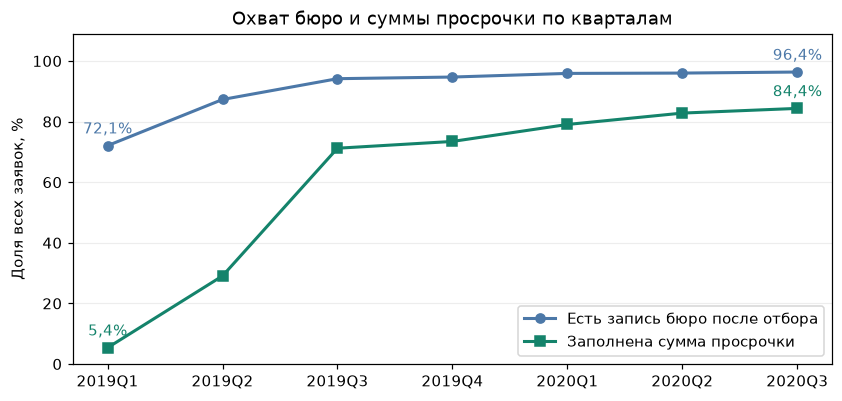

In [12]:
coverage_key = ("credit_bureau_a_1", "overdueamountmax2_398A")
coverage_plot = (aggregate_quarterly.loc[aggregate_quarterly.table.eq(coverage_key[0])
                                         & aggregate_quarterly.feature.eq(coverage_key[1])
                                         & aggregate_quarterly.full_quarter]
                 .merge(aggregate_source_coverage.drop(columns=["base_cases", "full_quarter"]),
                        on=["table", "quarter"], validate="one_to_one"))
assert len(coverage_plot) == full_quarter.sum()
fig, ax = plt.subplots(figsize=(8.9, 3.9))
for column, label, marker, color in [
    ("source_coverage_used_pct", "Есть запись бюро после отбора", "o", "#4C78A8"),
    ("case_coverage_pct", "Заполнена сумма просрочки", "s", "#14836B"),
]:
    ax.plot(coverage_plot.quarter, coverage_plot[column], marker=marker, label=label,
            color=color, linewidth=2)
    for i in [0, -1]:
        quarter = coverage_plot.quarter.iloc[i]
        value = coverage_plot[column].iloc[i]
        label_value = f"{value:.1f}%".replace(".", ",")
        ax.annotate(label_value, (quarter, value), xytext=(0, 8), textcoords="offset points",
                    ha="center", color=color)
ax.set(title="Охват бюро и суммы просрочки по кварталам", ylabel="Доля всех заявок, %", ylim=(0, 109))
ax.grid(axis="y", alpha=.22)
ax.legend(loc="lower right")
show_figure(fig)

Доля заявок с записями бюро выросла с **72,06% до 96,35%**, а заполненность поля — с **5,38% до 84,35%**. Среди заявок с записями бюро доля заполненных значений тоже выросла. Поэтому отдельно проверяем охват источника и конкретного поля. Если заменить пропуски нулями, разница в заполненности будет выглядеть как разница в сумме просрочки.

### Где меняются категории

У типа точки продаж `applprev_1.postype_4733339M` сравниваем доли обезличенных кодов **среди заявок с известным типом**. Синий цвет — 2019Q1, базовый квартал. Оранжевый — 2020Q3, квартал с наибольшим отличием от базового. Редкие коды объединены только на графике.

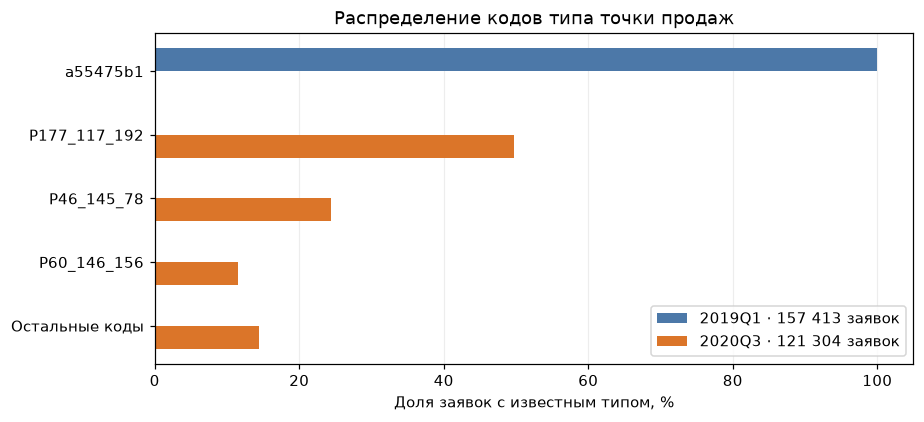

In [13]:
category_key = ("applprev_1", "postype_4733339M")
category_row = aggregate_stability.set_index(["table", "feature"]).loc[category_key]
compared = [category_row.reference_quarter, category_row.max_tv_quarter]
assert all(period in quarter_labels for period in compared)
codes = feature(*category_key)
category_counts = [
    codes[quarter_code == quarter_labels.index(period)].value_counts().loc[lambda counts: counts > 0]
    for period in compared
]
top_codes = list(dict.fromkeys(code for counts in category_counts for code in counts.head(3).index))
positions = np.arange(len(top_codes) + 1)
fig, ax = plt.subplots(figsize=(8.9, 3.9))
for j, (period, counts, color) in enumerate(zip(compared, category_counts, ["#4C78A8", "#DB7529"])):
    visible = counts.reindex(top_codes, fill_value=0)
    total = int(counts.sum())
    shares = 100 * np.r_[visible.to_numpy(), total - visible.sum()] / total
    count_label = f"{total:,}".replace(",", " ")
    ax.barh(positions + (j - .5) * .36, shares, height=.36,
            color=color, label=f"{period} · {count_label} заявок")
ax.set_yticks(positions, [*top_codes, "Остальные коды"])
ax.invert_yaxis()
ax.set(title="Распределение кодов типа точки продаж", xlabel="Доля заявок с известным типом, %", xlim=(0, 105))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=.22)
ax.legend(loc="lower right")
show_figure(fig)

В 2019Q1 почти все заполненные значения относятся к одному коду. В 2020Q3 преобладают другие коды, поэтому `TV ≈ 1`. Перед объединением кварталов нужно сверить, одинаково ли кодировался тип точки продаж.

Хотя бы один флаг получили **216 из 357** признаков. Флаги помогают выбрать поля для проверки. Полные результаты сохранены в отчётах `eda_aggregate_stability_*.csv`.

## 6. Совпадения и дубли после агрегации

Считаем корреляцию Пирсона отдельно для количественных полей и относительных дат. Для наиболее связанных пар проверяем, совпадают ли значения на общих заявках и какие заявки покрывает только одно поле. Точные дубли ищем среди 357 полей, сравнивая значения и пропуски. Полные результаты сохраняем в `eda_aggregate_feature_pairs.csv` и `eda_aggregate_exact_duplicates.csv`.

In [14]:
from collections import defaultdict
import hashlib


MIN_PAIR_CASES = 1_000
MATCH_PEARSON = .995
pair_fields = features_schema.set_index("column")
total_cases = len(data)
known_counts = feature_report.set_index("column").known_cases


def pair_correlations(names, family):
    matrix = data[names]
    corr = matrix.corr(method="pearson", min_periods=3).to_numpy()
    present = matrix.notna().to_numpy()
    overlap = np.zeros(corr.shape, dtype="float64")
    for start in range(0, total_cases, 30_000):
        block = present[start:start + 30_000].astype("float64")
        overlap += block.T @ block
    overlap = overlap.astype("int64")
    assert np.array_equal(overlap.diagonal(), known_counts.loc[names].to_numpy())
    i, j = np.triu_indices(len(names), k=1)
    left, right = np.asarray(names)[i], np.asarray(names)[j]
    left_table, right_table = pair_fields.loc[left, "table"].to_numpy(), pair_fields.loc[right, "table"].to_numpy()
    both = overlap[i, j]
    only_left, only_right = overlap[i, i] - both, overlap[j, j] - both
    return pd.DataFrame({
        "family": family,
        "scope": np.where(left_table == right_table, "within_source", "between_sources"),
        "column_left": left, "column_right": right,
        "table_left": left_table, "table_right": right_table,
        "feature_left": pair_fields.loc[left, "feature"].to_numpy(),
        "feature_right": pair_fields.loc[right, "feature"].to_numpy(),
        "pearson": corr[i, j], "abs_pearson": np.abs(corr[i, j]),
        "known_both": both, "shared_coverage_pct": 100 * both / total_cases,
        "known_left_only": only_left, "known_right_only": only_right,
        "coverage_gap_pp": 100 * np.abs(only_left - only_right) / total_cases,
    })


quantitative = pair_fields.index[pair_fields.semantic_type.str.startswith("numeric")].tolist()
dates = pair_fields.index[pair_fields.semantic_type.eq("date")].tolist()
assert len(quantitative) == 203 and len(dates) == 45
aggregate_pairs = pd.concat([
    pair_correlations(quantitative, "numeric"),
    pair_correlations(dates, "date"),
], ignore_index=True)
assert len(aggregate_pairs) == 21_493
aggregate_pairs = aggregate_pairs.sort_values(["abs_pearson", "known_both"], ascending=False,
                                              kind="stable").reset_index(drop=True)
ranking = aggregate_pairs.loc[aggregate_pairs.known_both.ge(MIN_PAIR_CASES) & aggregate_pairs.pearson.notna()]
top = ranking.groupby(["family", "scope"], sort=False).head(8).index
checked = top.union(aggregate_pairs.index[aggregate_pairs.abs_pearson.ge(MATCH_PEARSON)
                                           & aggregate_pairs.known_both.ge(MIN_PAIR_CASES)])
aggregate_pairs["spearman"] = np.nan
aggregate_pairs["equal_on_overlap"] = pd.Series(pd.NA, index=aggregate_pairs.index, dtype="Int64")
aggregate_pairs["equal_on_overlap_pct"] = np.nan
for idx in checked:
    row = aggregate_pairs.loc[idx]
    left = data[row.column_left].to_numpy()
    right = data[row.column_right].to_numpy()
    both = np.isfinite(left) & np.isfinite(right)
    x, z = left[both], right[both]
    assert len(x) == row.known_both
    equal = int(np.count_nonzero(x == z))
    aggregate_pairs.loc[idx, "equal_on_overlap"] = equal
    aggregate_pairs.loc[idx, "equal_on_overlap_pct"] = 100 * equal / len(x)
    if idx in top:
        aggregate_pairs.loc[idx, "spearman"] = pd.Series(x).rank().corr(pd.Series(z).rank())
assert aggregate_pairs.pearson.dropna().abs().le(1 + 1e-10).all()
assert aggregate_pairs.spearman.dropna().abs().le(1 + 1e-10).all()

# Отпечаток группирует кандидатов. Для каждой пары затем проверяется равенство массивов.
candidates = defaultdict(list)
for name, field in pair_fields.iterrows():
    if known_counts.loc[name] == 0:
        continue
    family = "numeric" if name in quantitative else field.semantic_type
    if name in numeric_set:
        values = data[name].to_numpy(copy=True)
        values[values == 0] = 0.0
        values[np.isnan(values)] = np.nan
    else:
        values = pd.util.hash_pandas_object(data[name], index=False).to_numpy()
    digest = hashlib.sha256(np.ascontiguousarray(values)).digest()
    candidates[(family, digest)].append(name)

duplicate_columns = ["family", "table_left", "feature_left", "table_right", "feature_right",
                     "column_left", "column_right", "known_cases", "missing_cases", "constant_known"]
duplicate_rows = []
constant = feature_report.set_index("column").constant_known
for (family, _), names in candidates.items():
    for i, left in enumerate(names):
        for right in names[i + 1:]:
            if left in numeric_set:
                equal = np.array_equal(data[left].to_numpy(), data[right].to_numpy(), equal_nan=True)
            else:
                equal = data[left].astype("object").equals(data[right].astype("object"))
            if equal:
                a, b = pair_fields.loc[left], pair_fields.loc[right]
                n = int(known_counts.loc[left])
                duplicate_rows.append([family, a.table, a.feature, b.table, b.feature, left, right,
                                       n, total_cases - n, bool(constant.loc[left])])
aggregate_duplicates = pd.DataFrame(duplicate_rows, columns=duplicate_columns)
aggregate_pairs.to_csv(FULL_DIR / "eda_aggregate_feature_pairs.csv", index=False)
aggregate_duplicates.to_csv(FULL_DIR / "eda_aggregate_exact_duplicates.csv", index=False)

same_where_known = aggregate_pairs.loc[
    aggregate_pairs.equal_on_overlap_pct.eq(100)
    & (aggregate_pairs.known_left_only + aggregate_pairs.known_right_only).gt(0)
]
pair_examples = [
    ("pmtnum_8L", "tenor_203L"),
    ("responsedate_4527233D", "recorddate_4527225D"),
    ("amount_4527230A", "amount_4917619A"),
]
display(aggregate_pairs.set_index(["feature_left", "feature_right"])
        .loc[pair_examples, ["pearson", "known_both", "equal_on_overlap_pct",
                             "known_left_only", "known_right_only"]]
        .round(3).rename(columns={
            "pearson": "Пирсон", "known_both": "Известны оба", "equal_on_overlap_pct": "Совпадение, %",
            "known_left_only": "Только первое", "known_right_only": "Только второе",
        }))

,,Пирсон,Известны оба,"Совпадение, %",Только первое,Только второе
feature_left,feature_right,,,,,
pmtnum_8L,tenor_203L,1.000,1191521,100.0,0,0
responsedate_4527233D,recorddate_4527225D,1.000,457934,100.0,202393,0
amount_4527230A,amount_4917619A,0.997,4233,0.0,453701,145966


Из **21 493 пар** выделяем три случая.

- У `pmtnum_8L` и `tenor_203L` совпали все 1 191 521 известных значений и все пропуски. Оставляем одно поле.
- Смещения налоговых дат совпали на всех 457 934 общих заявках. Дата ответа известна ещё у 202 393 заявок, поэтому для EDA сохраняем оба поля. Их доступность на момент решения нужно отдельно проверить перед использованием в модели.
- У двух налоговых сумм Пирсон около 0,997, но пересечение всего 4 233 заявки. Значения на пересечении различаются, а вне его поля покрывают разные заявки.

## 7. Рабочий список признаков

Исключаем по одному полю из двух подтверждённых пар дублей, затем убираем полностью пустые поля и константы без пропусков. Поле `residualamount_1093A` сохраняем, поскольку при одном известном значении сам факт заполнения различает заявки.

In [15]:
aggregate_dedup_decisions = pd.DataFrame([
    ("applprev_1", "pmtnum_8L", "tenor_203L"),
    ("person_1", "persontype_792L", "persontype_1072L"),
], columns=["table", "keep_feature", "drop_feature"])
aggregate_dedup_decisions["keep_column"] = [
    by_field.loc[(row.table, row.keep_feature)] for row in aggregate_dedup_decisions.itertuples()
]
aggregate_dedup_decisions["drop_column"] = [
    by_field.loc[(row.table, row.drop_feature)] for row in aggregate_dedup_decisions.itertuples()
]
confirmed = {frozenset((row.column_left, row.column_right)) for row in aggregate_duplicates.itertuples()}
planned = {frozenset((row.keep_column, row.drop_column)) for row in aggregate_dedup_decisions.itertuples()}
assert planned == confirmed, "Подтверждённые пары изменились. Перепроверь решения."

duplicate_columns = set(aggregate_dedup_decisions.drop_column)
empty = feature_report.known_cases.eq(0)
constant = feature_report.constant_known & feature_report.missing_cases.eq(0)
excluded = feature_report.loc[
    (empty | constant) & ~feature_report.column.isin(duplicate_columns),
    ["table", "feature", "column", "known_cases"],
].copy()
excluded["reason"] = np.where(excluded.known_cases.eq(0), "Полностью пустое", "Константа без пропусков")
assert len(excluded) == 4

metadata_columns = ["table", "feature", "column", "aggregation", "semantic_type"]
drop = duplicate_columns | set(excluded.column)
working_aggregate_features = features_schema.loc[
    ~features_schema.column.isin(drop), metadata_columns
].reset_index(drop=True)
working_aggregate_columns = working_aggregate_features.column.tolist()
keep = set(working_aggregate_columns)
partial_pair_columns = set(same_where_known[["column_left", "column_right"]].to_numpy().ravel())
assert set(feature_names) - keep == drop
assert partial_pair_columns.issubset(keep)
assert len(working_aggregate_features) == len(keep) == 351
working_aggregate_features.to_csv(FULL_DIR / "working_aggregate_features.csv", index=False)

duplicate_exclusions = aggregate_dedup_decisions[["table", "drop_feature"]].rename(
    columns={"drop_feature": "feature"}
).assign(reason="Точный дубль")
excluded_fields = pd.concat([duplicate_exclusions, excluded[["table", "feature", "reason"]]], ignore_index=True)
display(excluded_fields.rename(columns={"table": "Источник", "feature": "Поле", "reason": "Причина"}))
print(f"Признаки в рабочем списке — {len(feature_names)} → {len(working_aggregate_features)}")

working_dtype_counts = feature_dtypes.loc[working_aggregate_columns].value_counts()
working_dtype_counts = working_dtype_counts.reindex(dtype_counts.index, fill_value=0)
print("Типы хранения — " + ", ".join(f"{n} {kind}" for kind, n in working_dtype_counts.items()))

Признаки в рабочем списке — 357 → 351
Типы хранения — 247 float64, 104 category, 0 object, 0 int64


,Источник,Поле,Причина
0,applprev_1,tenor_203L,Точный дубль
1,person_1,persontype_1072L,Точный дубль
2,person_1,personindex_1023L,Константа без пропусков
3,person_1,persontype_792L,Константа без пропусков
4,person_1,relationshiptoclient_415T,Полностью пустое
5,person_1,relationshiptoclient_642T,Полностью пустое


Рабочий список для следующего этапа содержит **351 признак** и сохранён в `working_aggregate_features.csv`. Широкий анализ охватывает 357 полей до итогового отбора. Результаты проекта относятся к EDA. Качество прогноза предстоит оценить на более поздних данных.